In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torchgeo_bench.coordbench.config import CoordEvaluationConfig
from torchgeo_bench.coordbench.datasets import load_benchmarks
from torchgeo_bench.coordbench.splits import SPLITS, make_folds

In [2]:
bench = load_benchmarks("era5_ecmwf")[0]
rows = np.arange(len(bench.lat))
dates = pd.to_datetime(bench.posix_timestamp, unit="s")
STYLE = {"train": ("tab:blue", -0.25), "val": ("tab:green", 0), "test": ("tab:red", 0.25)}

/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


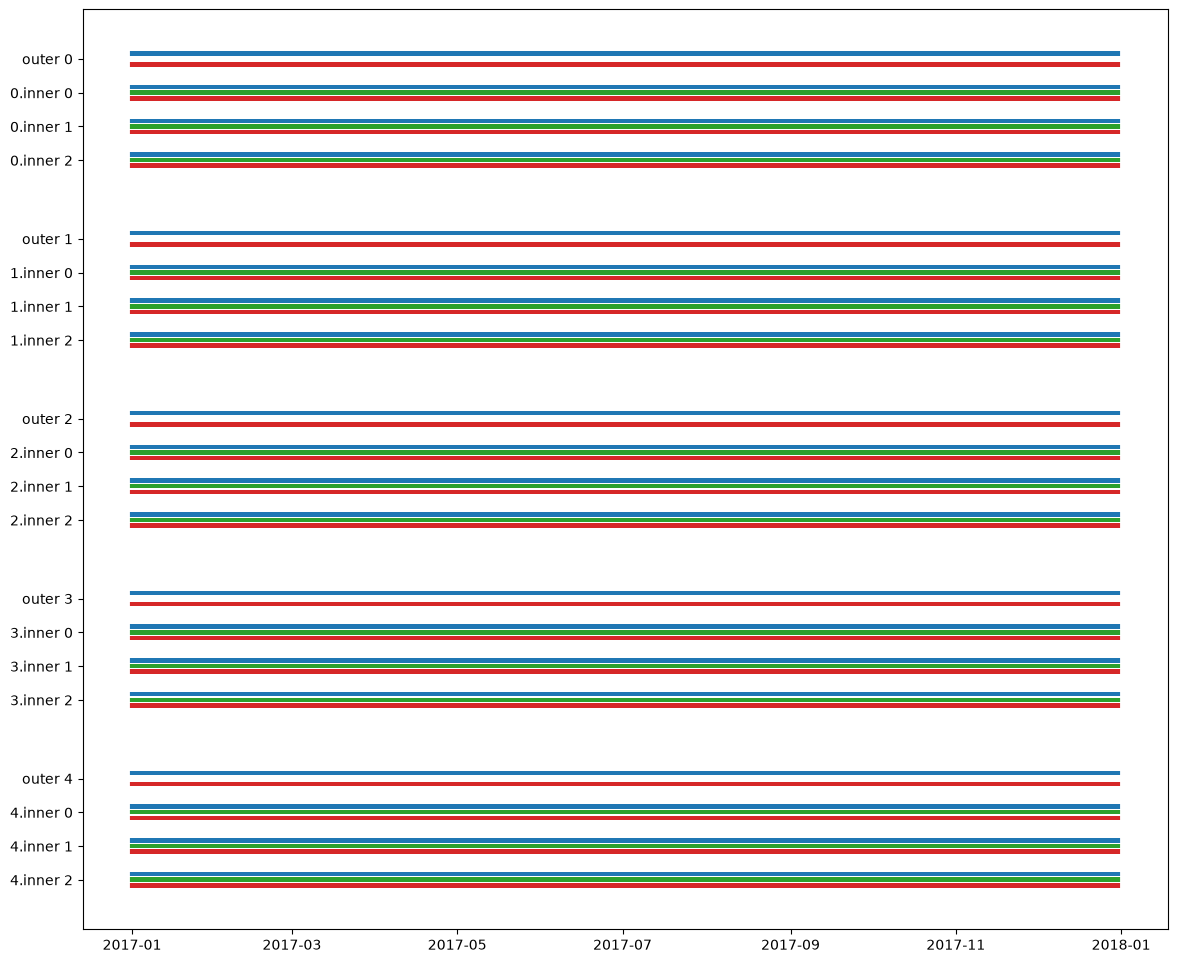

In [12]:
split = "random"
cfg = CoordEvaluationConfig(split=split, inner_split=split, folds=5, inner_folds=3, time_unit="month", max_train_size=12)
panels = []
for k, f in enumerate(make_folds(cfg, bench, rows, seed=0)):
    panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
    panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

gap_outer = 2   # spacing between outer groups
gap_inner = 1.5 # spacing between rows within a group

ys = []
offset = 0

for i, (name, _) in enumerate(panels):
    if i > 0 and name.startswith("outer"):
        offset += gap_outer
    ys.append(i * gap_inner + offset)

fig, ax = plt.subplots(figsize=(14, 0.3 * max(ys) + 1))

height = 0.2

for y, (_, roles) in zip(ys, panels):
    for role, idx in roles.items():
        d = dates[idx].unique()
        pos = y + STYLE[role][1]
        ax.vlines(d, pos - height / 2, pos + height / 2,
                  colors=STYLE[role][0], linewidth=3)

ax.set_yticks(ys, [name for name, _ in panels])
ax.invert_yaxis()  # outer 0 at the top

plt.show()

In [13]:
f = make_folds(cfg, bench, rows, seed=0)[0]; tr, va = f.inner[0]
print(len(tr), len(va), np.intersect1d(tr, va).size)  # last number should be 0


5840000 2920000 0


# Temporal Splits

## Temporal Forecast

### With random inner split

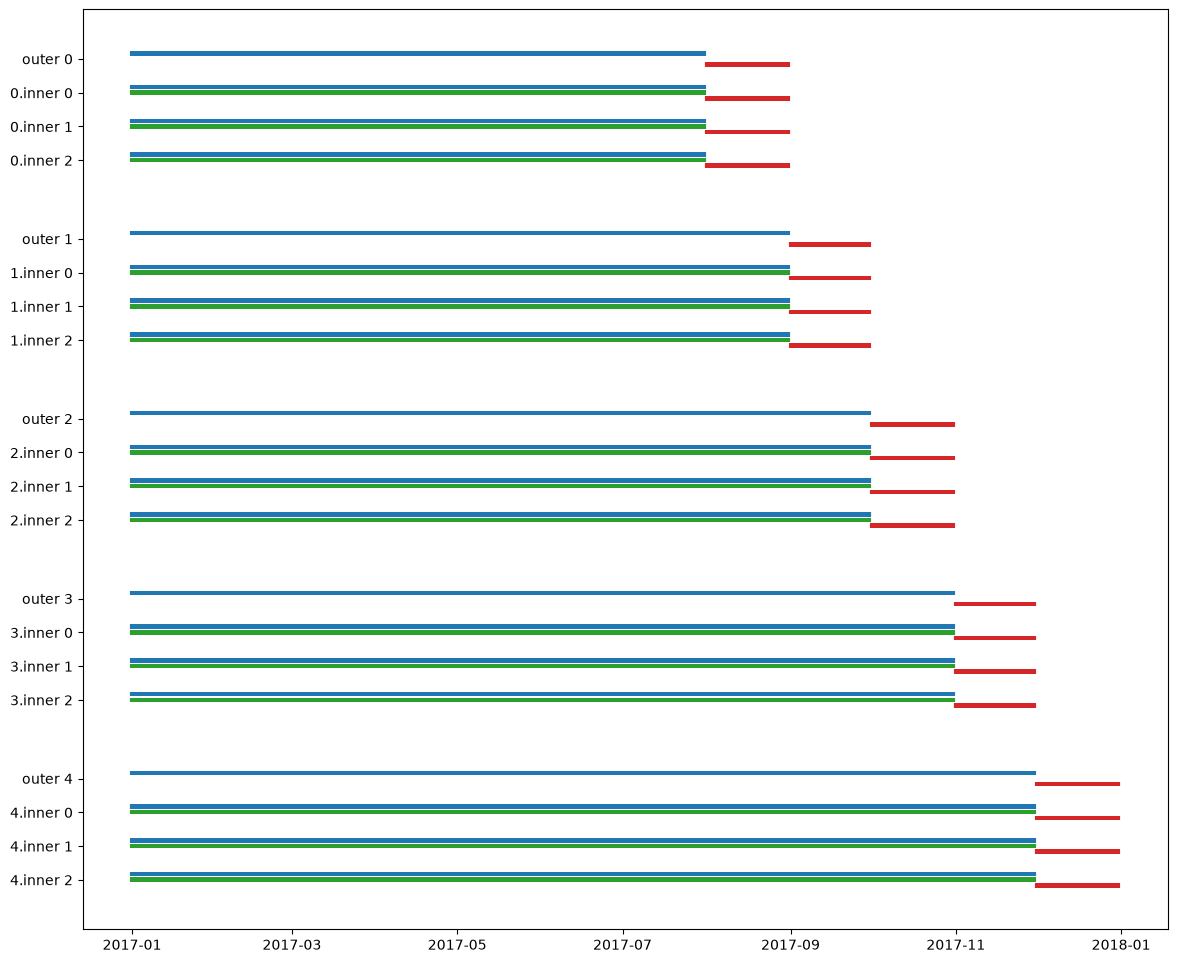

In [14]:
split = "temporal_forecast"
cfg = CoordEvaluationConfig(split=split, inner_split="random", folds=5, inner_folds=3, time_unit="month", max_train_size=12, test_size=1)
panels = []
for k, f in enumerate(make_folds(cfg, bench, rows, seed=0)):
    panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
    panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

gap_outer = 2   # spacing between outer groups
gap_inner = 1.5 # spacing between rows within a group

ys = []
offset = 0

for i, (name, _) in enumerate(panels):
    if i > 0 and name.startswith("outer"):
        offset += gap_outer
    ys.append(i * gap_inner + offset)

fig, ax = plt.subplots(figsize=(14, 0.3 * max(ys) + 1))

height = 0.2

for y, (_, roles) in zip(ys, panels):
    for role, idx in roles.items():
        d = dates[idx].unique()
        pos = y + STYLE[role][1]
        ax.vlines(d, pos - height / 2, pos + height / 2,
                  colors=STYLE[role][0], linewidth=3)

ax.set_yticks(ys, [name for name, _ in panels])
ax.invert_yaxis()  # outer 0 at the top

plt.show()

## Temporal Checkerboard

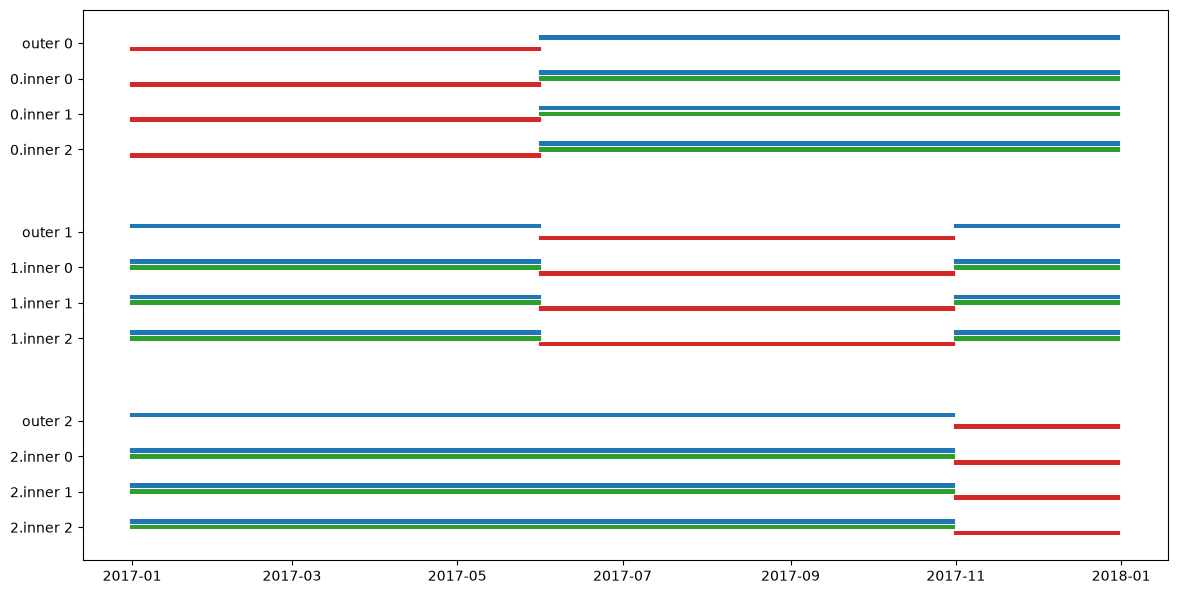

In [ ]:
split = "temporal_checkerboard"
cfg = CoordEvaluationConfig(split=split, inner_split="random", folds=5, inner_folds=3, time_unit="month", max_train_size=12, test_size=3)
panels = []
for k, f in enumerate(make_folds(cfg, bench, rows, seed=0)):
    panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
    panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

gap_outer = 2   # spacing between outer groups
gap_inner = 1.5 # spacing between rows within a group

ys = []
offset = 0

for i, (name, _) in enumerate(panels):
    if i > 0 and name.startswith("outer"):
        offset += gap_outer
    ys.append(i * gap_inner + offset)

fig, ax = plt.subplots(figsize=(14, 0.3 * max(ys) + 1))

height = 0.2

for y, (_, roles) in zip(ys, panels):
    for role, idx in roles.items():
        d = dates[idx].unique()
        pos = y + STYLE[role][1]
        ax.vlines(d, pos - height / 2, pos + height / 2,
                  colors=STYLE[role][0], linewidth=3)

ax.set_yticks(ys, [name for name, _ in panels])
ax.invert_yaxis()  # outer 0 at the top

plt.show()

## With Blocking (fixed train size)

## Temporal Forecast Block

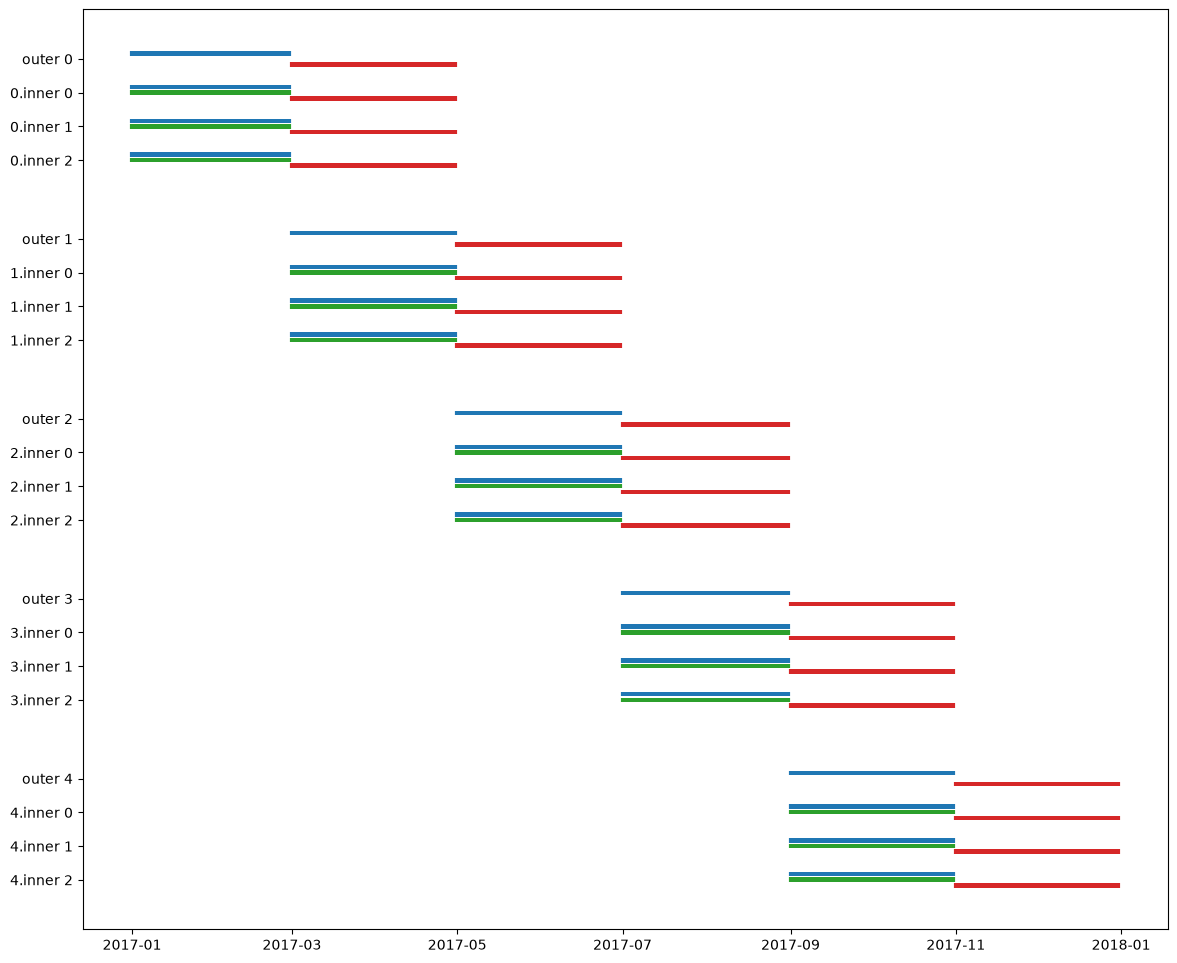

In [18]:
split = "temporal_forecast_block"
cfg = CoordEvaluationConfig(split=split, inner_split="random", folds=5, inner_folds=3, time_unit="month", max_train_size=2, test_size=2)
panels = []
for k, f in enumerate(make_folds(cfg, bench, rows, seed=0)):
    panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
    panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

gap_outer = 2   # spacing between outer groups
gap_inner = 1.5 # spacing between rows within a group

ys = []
offset = 0

for i, (name, _) in enumerate(panels):
    if i > 0 and name.startswith("outer"):
        offset += gap_outer
    ys.append(i * gap_inner + offset)

fig, ax = plt.subplots(figsize=(14, 0.3 * max(ys) + 1))

height = 0.2

for y, (_, roles) in zip(ys, panels):
    for role, idx in roles.items():
        d = dates[idx].unique()
        pos = y + STYLE[role][1]
        ax.vlines(d, pos - height / 2, pos + height / 2,
                  colors=STYLE[role][0], linewidth=3)

ax.set_yticks(ys, [name for name, _ in panels])
ax.invert_yaxis()  # outer 0 at the top

plt.show()

## Temporal Contiguous Block

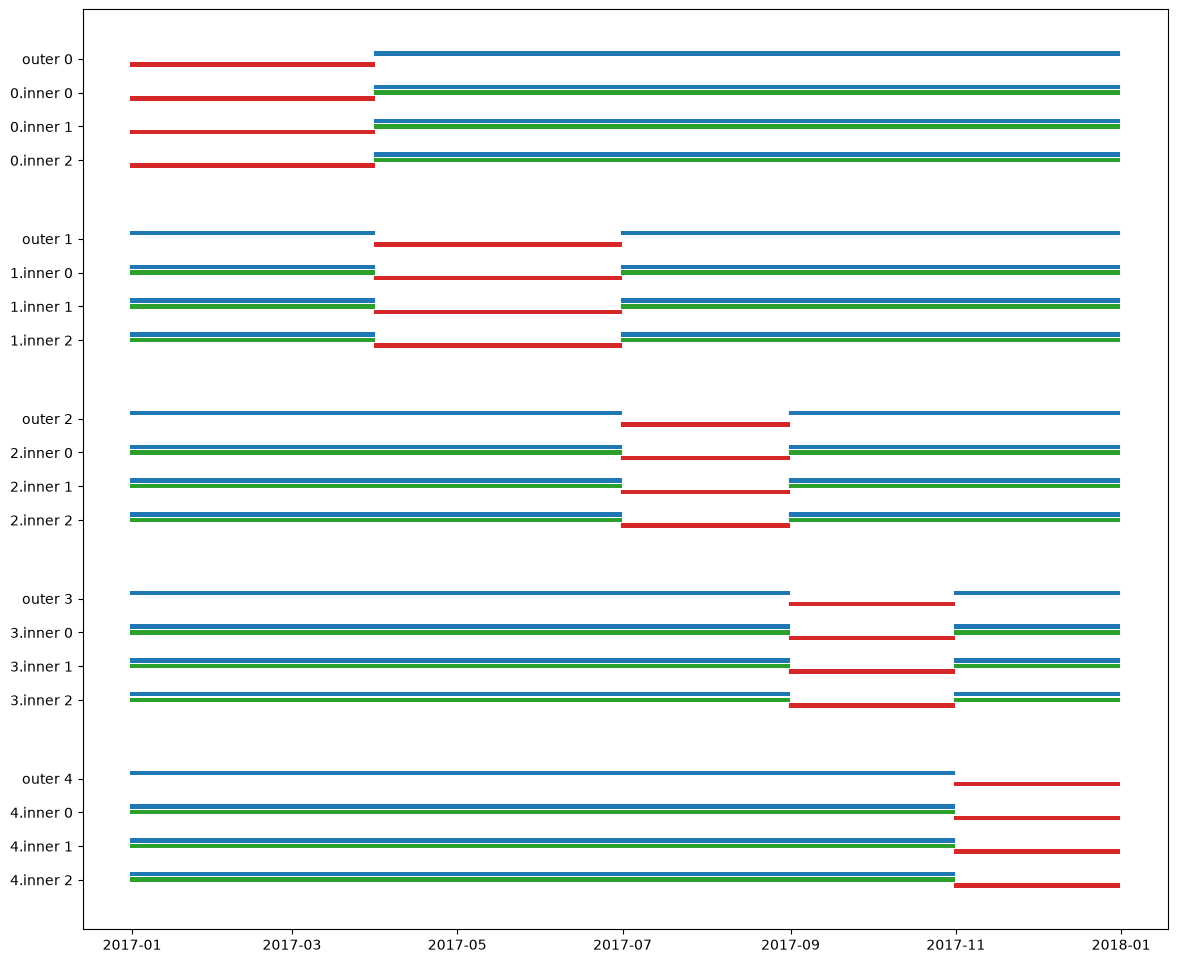

In [ ]:
split = "temporal_contiguous_block"
cfg = CoordEvaluationConfig(split=split, inner_split="random", folds=5, inner_folds=3, time_unit="month", max_train_size=2, test_size=2)
panels = []
for k, f in enumerate(make_folds(cfg, bench, rows, seed=0)):
    panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
    panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

gap_outer = 2   # spacing between outer groups
gap_inner = 1.5 # spacing between rows within a group

ys = []
offset = 0

for i, (name, _) in enumerate(panels):
    if i > 0 and name.startswith("outer"):
        offset += gap_outer
    ys.append(i * gap_inner + offset)

fig, ax = plt.subplots(figsize=(14, 0.3 * max(ys) + 1))

height = 0.2

for y, (_, roles) in zip(ys, panels):
    for role, idx in roles.items():
        d = dates[idx].unique()
        pos = y + STYLE[role][1]
        ax.vlines(d, pos - height / 2, pos + height / 2,
                  colors=STYLE[role][0], linewidth=3)

ax.set_yticks(ys, [name for name, _ in panels])
ax.invert_yaxis()  # outer 0 at the top

plt.show()